# Deconstructing NEWS2

**Deconstructing the National Early Warning Score 2 (NEWS2): An Exhaustive Combinatorial Analysis Reveals the Hierarchy of Its Seven Parameters in Prehospital and Hospital Care**

This notebook evaluates all 127 non-empty subsets of the seven NEWS2 parameters in prehospital and hospital care, for 30-day mortality and ICU admission. Predictions are sums of the retained NEWS2 component points.

## Methods and interpretation

- Stratified outer cross-validation evaluates each subset. Inner folds select classification thresholds using balanced accuracy; outer test labels are not used for threshold selection.
- AUC attribution uses the mean outer-fold AUC for every subset, including the full score. The empty subset is assigned AUC = 0.5.
- Exact Shapley contributions sum to the full-score AUC minus 0.5. Dividing each contribution by that total gives percentages summing to 100%; negative contributions are retained.
- These bars attribute discrimination, not causality or individual patient risk. They differ from the optional patient-level SHAP plots of NEWS2 points.

## Reproduction

Run from the repository root after installing `requirements.txt`. Supply `data/NEWs2.csv` locally. Existing outputs are historical; newly added plots require running their cells after the corresponding experiments. The presentation edits were validated without running the study data.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

from functions.news import calculate_NEWS2
from functions.news2_scale_utils import (
    add_stratified_folds,
    make_marginal_ablation_plot,
)
from functions.news2_scale_deconstruction import (
    evaluate_component_raw_deltas,
    make_component_delta_auc_plot,
    make_scale_branching_subset_plot,
    run_resumable_scale_search,
)
from functions.news2_auc_shapley import plot_news2_auc_attribution
from functions.news2_auc_dominance import plot_news2_auc_dominance


def save_subset_plot(figure, name, folder):
    """Save a Plotly figure as PDF and high-resolution PNG, then display it."""
    output_dir = OUTPUT_DIR / folder
    output_dir.mkdir(parents=True, exist_ok=True)
    figure.write_image(str(output_dir / f"{name}.pdf"))
    figure.write_image(str(output_dir / f"{name}.png"), scale=3)
    figure.show()


## 1. Data and analysis configuration

Prepare both cohorts using the existing study-specific mappings. Set the input and output paths below before running.

In [2]:
raw_data = pd.read_csv(
    'data/NEWs2.csv', sep=';', encoding='utf-8-sig', low_memory=False
)
for column in ['TT-1', 'TT-H']:
    raw_data[column] = pd.to_numeric(
        raw_data[column].astype('string').str.strip().str.replace(',', '.', regex=False),
        errors='coerce',
    )

FEATURES = [
    'resp_rate', 'blod_oxy', 'oxigen', 'blod_pres',
    'heart_rate', 'consciousness', 'temp',
]
OUTCOMES = ['M30D', 'UVI']
FOLD_COLUMN = 'cv_fold'
N_OUTER_FOLDS = 10
RANDOM_STATE = 42
REFERENCE_THRESHOLD = 5
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))
OUTPUT_DIR = Path('data/outputs/news2_scale_deconstruction')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def prepare_cohort(suffix):
    cohort = pd.DataFrame(index=raw_data.index)
    cohort['#ID'] = raw_data['#ID']
    cohort['resp_rate'] = raw_data[f'FR-{suffix}']
    cohort['blod_oxy'] = raw_data[f'SpO2-{suffix}']
    cohort['oxigen'] = np.where(raw_data[f'FiO2-{suffix}'] > 0.21, 1, 0)
    cohort['blod_pres'] = raw_data[f'TAS-{suffix}']
    cohort['heart_rate'] = raw_data[f'FC-{suffix}']
    cohort['temp'] = raw_data[f'TT-{suffix}']
    gcs_total = (
        raw_data[f'GCS.O-{suffix}']
        + raw_data[f'GCS.V-{suffix}']
        + raw_data[f'GCS.M-{suffix}']
    )
    cohort['consciousness'] = np.where(gcs_total == 15, 1, 0)
    cohort['M30D'] = raw_data['Mortalidad a 30 dias']
    cohort['UVI'] = raw_data['UVI']
    cohort = cohort.dropna(subset=FEATURES).copy()
    return calculate_NEWS2(cohort, FEATURES)

data_pre = prepare_cohort('1')
data_hosp = prepare_cohort('H')
pd.DataFrame({
    'cohort': ['Prehospital', 'Hospital'],
    'rows': [len(data_pre), len(data_hosp)],
    'M30D rate': [data_pre['M30D'].mean(), data_hosp['M30D'].mean()],
    'UVI rate': [data_pre['UVI'].mean(), data_hosp['UVI'].mean()],
    'NEWS2_mean': [data_pre['NEWS2'].mean(), data_hosp['NEWS2'].mean()],
})

,cohort,rows,M30D rate,UVI rate,NEWS2_mean
0,Prehospital,17976,0.114987,0.156773,4.824321
1,Hospital,16852,0.115773,0.154056,4.182412


## 2. Cross-validation experiment helper

The outer test fold is never used to choose its threshold. Inner validation folds contribute equally to threshold selection. Searches preserve checkpoints for resumption.

In [3]:
def run_scale_experiment(cohort_data, cohort_name, cohort_slug, outcome):
    experiment_id = f'{outcome.lower()}_news2_scale_10fold_{cohort_slug}'
    results_path = OUTPUT_DIR / f'{outcome.lower()}_{cohort_slug}_results.csv'
    folds_path = OUTPUT_DIR / f'{outcome.lower()}_{cohort_slug}_assignments.csv'

    model_data = (
        cohort_data.loc[:, FEATURES + [outcome]].dropna().copy()
    )
    model_data[outcome] = model_data[outcome].astype(int)
    model_data = add_stratified_folds(
        model_data,
        target=outcome,
        fold_column=FOLD_COLUMN,
        n_splits=N_OUTER_FOLDS,
        random_state=RANDOM_STATE,
    )
    model_data.to_csv(folds_path, index=False, encoding='utf-8-sig')

    reference_data = cohort_data.loc[:, ['NEWS2', outcome]].dropna()
    reference_auc = roc_auc_score(reference_data[outcome], reference_data['NEWS2'])
    results = run_resumable_scale_search(
        model_data,
        feature_order=FEATURES,
        target=outcome,
        fold_column=FOLD_COLUMN,
        experiment_id=experiment_id,
        results_path=results_path,
        reference_threshold=REFERENCE_THRESHOLD,
        n_jobs=N_JOBS,
    )
    print(f'{cohort_name} / {outcome}: {len(model_data):,} rows')
    print(f'NEWS2 reference AUC: {reference_auc:.3f}')
    print(f'Results: {results_path}')
    return results, reference_auc

## 3. Prehospital care

### Prehospital — 30-day mortality

In [4]:
results_m30d_pre, auc_m30d_pre = run_scale_experiment(
    data_pre, 'Prehospital', 'prehosp', 'M30D'
)
results_m30d_pre.sort_values(
    ['balanced_accuracy', 'auc'], ascending=False
).loc[:, [
    'subset_label', 'n_features', 'auc', 'auc_sd',
    'balanced_accuracy', 'balanced_accuracy_sd',
    'sensitivity', 'specificity', 'threshold_mean', 'threshold_sd',
]].head(15)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Prehospital / M30D: 17,976 rows
NEWS2 reference AUC: 0.815
Results: data/outputs/news2_scale_deconstruction/m30d_prehosp_results.csv


,subset_label,n_features,auc,auc_sd,balanced_accuracy,balanced_accuracy_sd,sensitivity,specificity,threshold_mean,threshold_sd
64,blod_oxy + oxigen + consciousness,3,0.821140,0.012655,0.758707,0.009193,0.828746,0.688667,3.0,0.000000
99,blod_oxy + consciousness,2,0.804876,0.009200,0.756225,0.008580,0.809892,0.702558,3.0,0.000000
100,oxigen + consciousness,2,0.772459,0.014293,0.750631,0.016101,0.757593,0.743668,2.0,0.000000
29,blod_oxy + oxigen + consciousness + temp,4,0.817273,0.013062,0.749834,0.013787,0.747955,0.751713,4.0,0.000000
65,blod_oxy + blod_pres + consciousness,3,0.811026,0.012378,0.748892,0.008947,0.850038,0.647747,3.0,0.000000
8,resp_rate + blod_oxy + oxigen + blod_pres + co...,5,0.823735,0.015685,0.748751,0.013605,0.748429,0.749074,5.0,0.000000
9,blod_oxy + oxigen + blod_pres + consciousness ...,5,0.819790,0.013499,0.748093,0.010851,0.801170,0.695016,4.0,0.000000
30,resp_rate + blod_oxy + oxigen + consciousness,4,0.819681,0.013152,0.747204,0.010713,0.758597,0.735812,4.0,0.000000
31,blod_oxy + oxigen + blod_pres + consciousness,4,0.824729,0.014176,0.746894,0.009968,0.845603,0.648186,3.1,0.316228
66,resp_rate + oxigen + consciousness,3,0.801582,0.014018,0.742874,0.013698,0.831652,0.654096,3.0,0.000000


#### Shapley attribution of discrimination

Bars allocate the full score’s AUC above chance among the seven parameters. Percentages sum to 100% within this experiment; negative values represent a negative average incremental AUC contribution. Parameter order is fixed across experiments; horizontal ranges adapt to each plot.

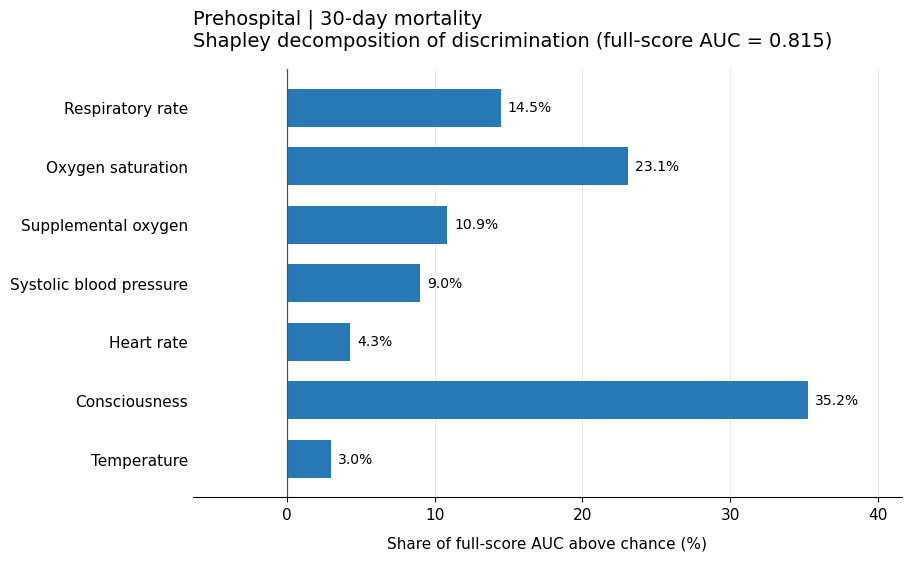

In [5]:
attribution_m30d_pre, figure_m30d_pre = plot_news2_auc_attribution(
    results_m30d_pre, FEATURES,
    cohort="Prehospital", outcome="M30D",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_m30d_pre)

#### Dominance analysis of discrimination

Each cell compares the incremental AUC gained by adding the row parameter versus the column parameter to the **same** subset of the other five parameters (32 contexts, including the empty subset with AUC = 0.5).

- **32/32 · CD:** the row parameter adds strictly more AUC in every context: complete dominance.
- **Intermediate counts:** superiority depends on the context; complete dominance is not established.
- Numerical ties within `1e-10` are not wins. Identical predictors can therefore have 0 wins in both directions.

Colors use the same 0–1 scale in all four experiments. These descriptive comparisons use mean outer-fold AUCs for fixed NEWS2 partial scores; they are not significance tests. Full pairwise counts and context-specific AUC gains are exported as CSV files. The 32 common contexts differ from the 63 non-empty removal pairs per parameter in the ablation plots.

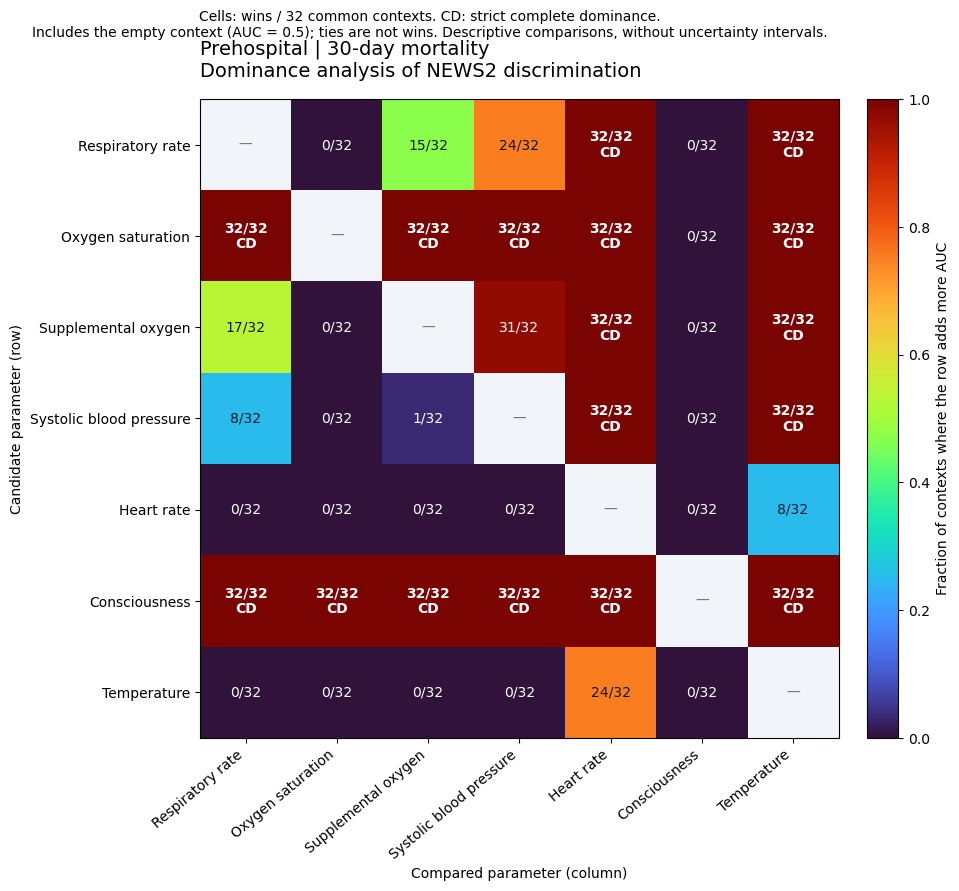

In [6]:
dominance_m30d_pre, dominance_figure_m30d_pre = plot_news2_auc_dominance(
    results_m30d_pre, FEATURES,
    cohort='Prehospital', outcome='M30D',
    output_dir=OUTPUT_DIR / "dominance_auc",
)
plt.show()
plt.close(dominance_figure_m30d_pre)

#### Subset performance and parameter removal

In [7]:
save_subset_plot(
    make_scale_branching_subset_plot(
    results_m30d_pre, FEATURES, news2_auc=auc_m30d_pre,
    title='M30D in prehospital patients',
    ),
    "m30d_pre_parallel_plots", "parallel_plots",
)

In [8]:
save_subset_plot(
    make_marginal_ablation_plot(
    results_m30d_pre, FEATURES, title='M30D in prehospital patients'
    ),
    "m30d_pre_boxplots", "boxplots",
)

### Prehospital — ICU admission

In [9]:
results_uvi_pre, auc_uvi_pre = run_scale_experiment(
    data_pre, 'Prehospital', 'prehosp', 'UVI'
)
results_uvi_pre.sort_values(
    ['balanced_accuracy', 'auc'], ascending=False
).loc[:, [
    'subset_label', 'n_features', 'auc', 'auc_sd',
    'balanced_accuracy', 'balanced_accuracy_sd',
    'sensitivity', 'specificity', 'threshold_mean', 'threshold_sd',
]].head(15)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Prehospital / UVI: 17,975 rows
NEWS2 reference AUC: 0.758
Results: data/outputs/news2_scale_deconstruction/uvi_prehosp_results.csv


,subset_label,n_features,auc,auc_sd,balanced_accuracy,balanced_accuracy_sd,sensitivity,specificity,threshold_mean,threshold_sd
64,oxigen + blod_pres + consciousness,3,0.750668,0.014118,0.726715,0.010739,0.694110,0.759319,3.0,0.0
99,blod_pres + consciousness,2,0.738790,0.012196,0.725326,0.012510,0.682757,0.767896,3.0,0.0
100,oxigen + consciousness,2,0.739300,0.013023,0.721742,0.012488,0.624919,0.818566,3.0,0.0
120,consciousness,1,0.721742,0.012488,0.721742,0.012488,0.624919,0.818566,3.0,0.0
101,blod_oxy + consciousness,2,0.754178,0.011500,0.720670,0.013691,0.728534,0.712806,3.0,0.0
65,blod_oxy + oxigen + consciousness,3,0.763925,0.011452,0.717984,0.012911,0.738469,0.697499,3.0,0.0
66,oxigen + consciousness + temp,3,0.752090,0.018653,0.717969,0.011585,0.703340,0.732598,3.0,0.0
102,consciousness + temp,2,0.742563,0.018499,0.717572,0.013049,0.677079,0.758065,2.0,0.0
67,resp_rate + oxigen + consciousness,3,0.755062,0.011761,0.715245,0.013726,0.764726,0.665765,3.0,0.0
68,blod_oxy + blod_pres + consciousness,3,0.758566,0.010914,0.714626,0.011443,0.771471,0.657782,3.0,0.0


#### Shapley attribution of discrimination

Bars allocate the full score’s AUC above chance among the seven parameters. Percentages sum to 100% within this experiment; negative values represent a negative average incremental AUC contribution. Parameter order is fixed across experiments; horizontal ranges adapt to each plot.

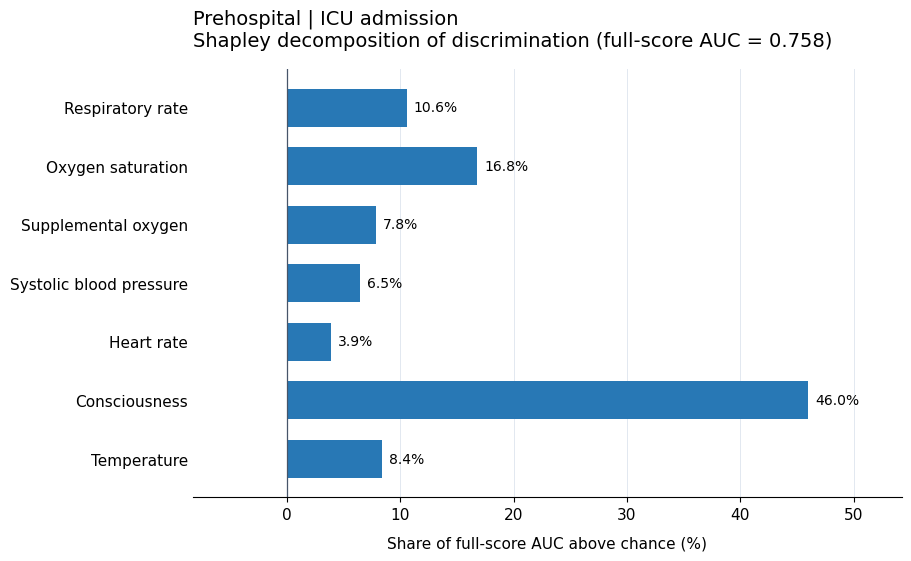

In [10]:
attribution_uvi_pre, figure_uvi_pre = plot_news2_auc_attribution(
    results_uvi_pre, FEATURES,
    cohort="Prehospital", outcome="UVI",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_uvi_pre)

#### Dominance analysis of discrimination

Each cell compares the incremental AUC gained by adding the row parameter versus the column parameter to the **same** subset of the other five parameters (32 contexts, including the empty subset with AUC = 0.5).

- **32/32 · CD:** the row parameter adds strictly more AUC in every context: complete dominance.
- **Intermediate counts:** superiority depends on the context; complete dominance is not established.
- Numerical ties within `1e-10` are not wins. Identical predictors can therefore have 0 wins in both directions.

Colors use the same 0–1 scale in all four experiments. These descriptive comparisons use mean outer-fold AUCs for fixed NEWS2 partial scores; they are not significance tests. Full pairwise counts and context-specific AUC gains are exported as CSV files. The 32 common contexts differ from the 63 non-empty removal pairs per parameter in the ablation plots.

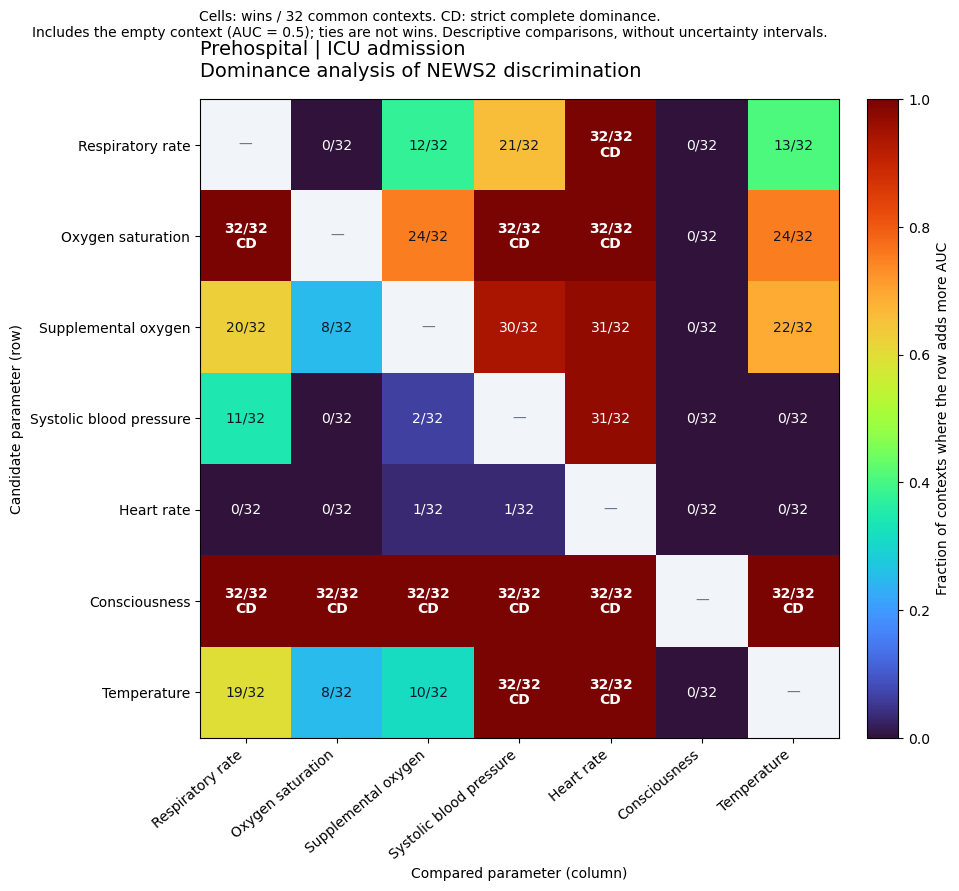

In [11]:
dominance_uvi_pre, dominance_figure_uvi_pre = plot_news2_auc_dominance(
    results_uvi_pre, FEATURES,
    cohort='Prehospital', outcome='UVI',
    output_dir=OUTPUT_DIR / "dominance_auc",
)
plt.show()
plt.close(dominance_figure_uvi_pre)

#### Subset performance and parameter removal

In [12]:
save_subset_plot(
    make_scale_branching_subset_plot(
    results_uvi_pre, FEATURES, news2_auc=auc_uvi_pre,
    title='UVI in prehospital patients',
    ),
    "uvi_pre_parallel_plots", "parallel_plots",
)

In [13]:
save_subset_plot(
    make_marginal_ablation_plot(
    results_uvi_pre, FEATURES, title='UVI in prehospital patients'
    ),
    "uvi_pre_boxplots", "boxplots",
)

## 4. Hospital care

### Hospital — 30-day mortality

In [14]:
results_m30d_hosp, auc_m30d_hosp = run_scale_experiment(
    data_hosp, 'Hospital', 'hosp', 'M30D'
)
results_m30d_hosp.sort_values(
    ['balanced_accuracy', 'auc'], ascending=False
).loc[:, [
    'subset_label', 'n_features', 'auc', 'auc_sd',
    'balanced_accuracy', 'balanced_accuracy_sd',
    'sensitivity', 'specificity', 'threshold_mean', 'threshold_sd',
]].head(15)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Hospital / M30D: 16,852 rows
NEWS2 reference AUC: 0.862
Results: data/outputs/news2_scale_deconstruction/m30d_hosp_results.csv


,subset_label,n_features,auc,auc_sd,balanced_accuracy,balanced_accuracy_sd,sensitivity,specificity,threshold_mean,threshold_sd
8,resp_rate + blod_oxy + oxigen + blod_pres + co...,5,0.865328,0.011780,0.799597,0.010172,0.809851,0.789343,5.0,0.0
9,blod_oxy + oxigen + blod_pres + heart_rate + c...,5,0.865482,0.009738,0.798455,0.007926,0.781661,0.815248,5.0,0.0
29,blod_oxy + oxigen + blod_pres + consciousness,4,0.868043,0.010945,0.798200,0.008518,0.740149,0.856252,5.0,0.0
30,resp_rate + oxigen + blod_pres + consciousness,4,0.864683,0.011021,0.797862,0.009859,0.758598,0.837126,5.0,0.0
31,resp_rate + blod_oxy + oxigen + consciousness,4,0.857834,0.009654,0.797506,0.009138,0.773456,0.821556,5.0,0.0
10,resp_rate + oxigen + blod_pres + heart_rate + ...,5,0.861659,0.008772,0.796751,0.005990,0.793959,0.799544,5.0,0.0
99,resp_rate + consciousness,2,0.819780,0.011108,0.795766,0.012829,0.797559,0.793974,3.0,0.0
11,resp_rate + blod_oxy + oxigen + heart_rate + c...,5,0.856082,0.009624,0.795765,0.005331,0.807287,0.784243,5.0,0.0
64,resp_rate + oxigen + consciousness,3,0.851829,0.008782,0.795761,0.010353,0.838553,0.752970,3.0,0.0
32,resp_rate + oxigen + consciousness + temp,4,0.856132,0.011894,0.795044,0.009561,0.816515,0.773573,4.0,0.0


#### Shapley attribution of discrimination

Bars allocate the full score’s AUC above chance among the seven parameters. Percentages sum to 100% within this experiment; negative values represent a negative average incremental AUC contribution. Parameter order is fixed across experiments; horizontal ranges adapt to each plot.

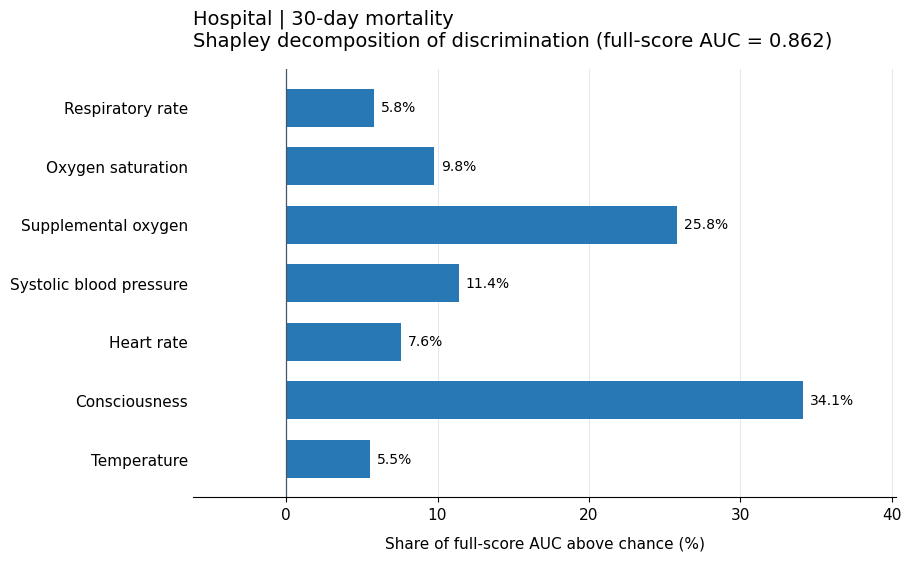

In [15]:
attribution_m30d_hosp, figure_m30d_hosp = plot_news2_auc_attribution(
    results_m30d_hosp, FEATURES,
    cohort="Hospital", outcome="M30D",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_m30d_hosp)

#### Dominance analysis of discrimination

Each cell compares the incremental AUC gained by adding the row parameter versus the column parameter to the **same** subset of the other five parameters (32 contexts, including the empty subset with AUC = 0.5).

- **32/32 · CD:** the row parameter adds strictly more AUC in every context: complete dominance.
- **Intermediate counts:** superiority depends on the context; complete dominance is not established.
- Numerical ties within `1e-10` are not wins. Identical predictors can therefore have 0 wins in both directions.

Colors use the same 0–1 scale in all four experiments. These descriptive comparisons use mean outer-fold AUCs for fixed NEWS2 partial scores; they are not significance tests. Full pairwise counts and context-specific AUC gains are exported as CSV files. The 32 common contexts differ from the 63 non-empty removal pairs per parameter in the ablation plots.

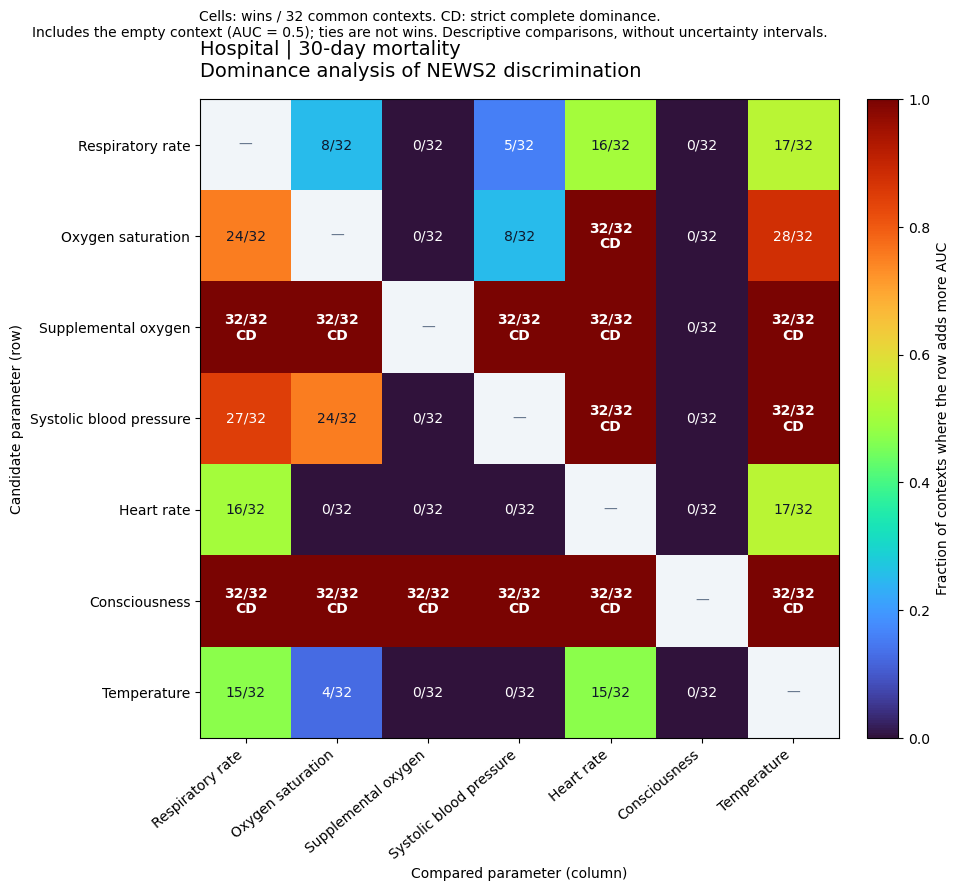

In [16]:
dominance_m30d_hosp, dominance_figure_m30d_hosp = plot_news2_auc_dominance(
    results_m30d_hosp, FEATURES,
    cohort='Hospital', outcome='M30D',
    output_dir=OUTPUT_DIR / "dominance_auc",
)
plt.show()
plt.close(dominance_figure_m30d_hosp)

#### Subset performance and parameter removal

In [17]:
save_subset_plot(
    make_scale_branching_subset_plot(
    results_m30d_hosp, FEATURES, news2_auc=auc_m30d_hosp,
    title='M30D in hospitalized patients',
    ),
    "m30d_hosp_parallel_plots", "parallel_plots",
)
save_subset_plot(
    make_marginal_ablation_plot(
    results_m30d_hosp, FEATURES, title='M30D in hospitalized patients'
    ),
    "m30d_hosp_boxplots", "boxplots",
)

### Hospital — ICU admission

In [18]:
results_uvi_hosp, auc_uvi_hosp = run_scale_experiment(
    data_hosp, 'Hospital', 'hosp', 'UVI'
)
results_uvi_hosp.sort_values(
    ['balanced_accuracy', 'auc'], ascending=False
).loc[:, [
    'subset_label', 'n_features', 'auc', 'auc_sd',
    'balanced_accuracy', 'balanced_accuracy_sd',
    'sensitivity', 'specificity', 'threshold_mean', 'threshold_sd',
]].head(15)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Hospital / UVI: 16,851 rows
NEWS2 reference AUC: 0.801
Results: data/outputs/news2_scale_deconstruction/uvi_hosp_results.csv


,subset_label,n_features,auc,auc_sd,balanced_accuracy,balanced_accuracy_sd,sensitivity,specificity,threshold_mean,threshold_sd
29,resp_rate + oxigen + blod_pres + consciousness,4,0.821112,0.013907,0.775291,0.015873,0.697620,0.852962,5.0,0.000000
30,oxigen + blod_pres + heart_rate + consciousness,4,0.833162,0.013269,0.774937,0.012844,0.659871,0.890003,5.0,0.000000
64,oxigen + blod_pres + consciousness,3,0.833085,0.011194,0.773420,0.011430,0.740385,0.806455,3.0,0.000000
8,resp_rate + oxigen + blod_pres + heart_rate + ...,5,0.817974,0.014221,0.772356,0.017730,0.729981,0.814731,5.0,0.000000
9,oxigen + blod_pres + heart_rate + consciousnes...,5,0.829609,0.013998,0.772177,0.015429,0.700301,0.844053,5.0,0.000000
10,resp_rate + oxigen + blod_pres + consciousness...,5,0.821915,0.015102,0.771477,0.017900,0.730748,0.812205,5.0,0.000000
31,resp_rate + oxigen + heart_rate + consciousness,4,0.816401,0.012422,0.770833,0.016706,0.743842,0.797825,4.0,0.000000
32,oxigen + heart_rate + consciousness + temp,4,0.831565,0.012454,0.770433,0.015664,0.654090,0.886776,5.0,0.000000
65,oxigen + heart_rate + consciousness,3,0.834293,0.012294,0.770415,0.016069,0.653704,0.887127,4.0,0.000000
33,resp_rate + oxigen + consciousness + temp,4,0.822157,0.013147,0.768620,0.015040,0.749238,0.788002,4.0,0.000000


#### Shapley attribution of discrimination

Bars allocate the full score’s AUC above chance among the seven parameters. Percentages sum to 100% within this experiment; negative values represent a negative average incremental AUC contribution. Parameter order is fixed across experiments; horizontal ranges adapt to each plot.

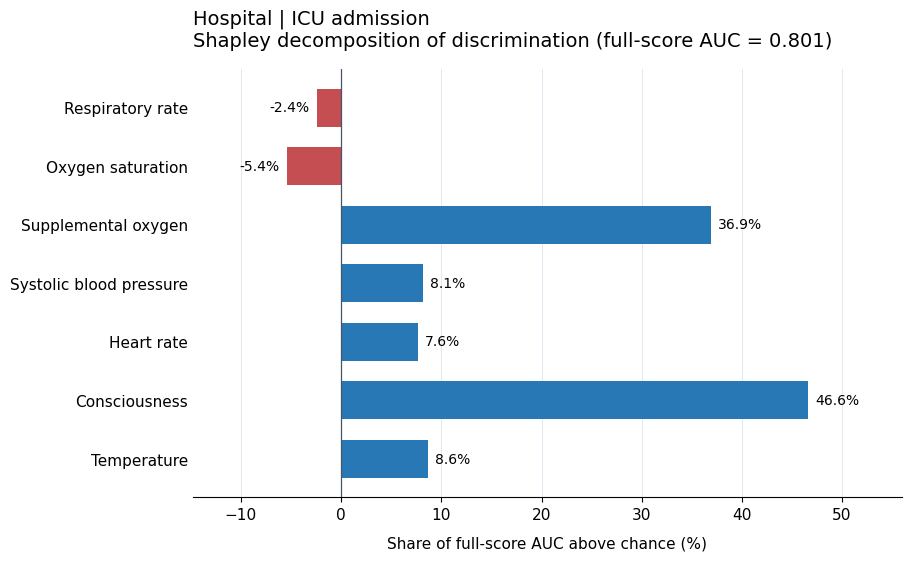

In [19]:
attribution_uvi_hosp, figure_uvi_hosp = plot_news2_auc_attribution(
    results_uvi_hosp, FEATURES,
    cohort="Hospital", outcome="UVI",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_uvi_hosp)

#### Dominance analysis of discrimination

Each cell compares the incremental AUC gained by adding the row parameter versus the column parameter to the **same** subset of the other five parameters (32 contexts, including the empty subset with AUC = 0.5).

- **32/32 · CD:** the row parameter adds strictly more AUC in every context: complete dominance.
- **Intermediate counts:** superiority depends on the context; complete dominance is not established.
- Numerical ties within `1e-10` are not wins. Identical predictors can therefore have 0 wins in both directions.

Colors use the same 0–1 scale in all four experiments. These descriptive comparisons use mean outer-fold AUCs for fixed NEWS2 partial scores; they are not significance tests. Full pairwise counts and context-specific AUC gains are exported as CSV files. The 32 common contexts differ from the 63 non-empty removal pairs per parameter in the ablation plots.

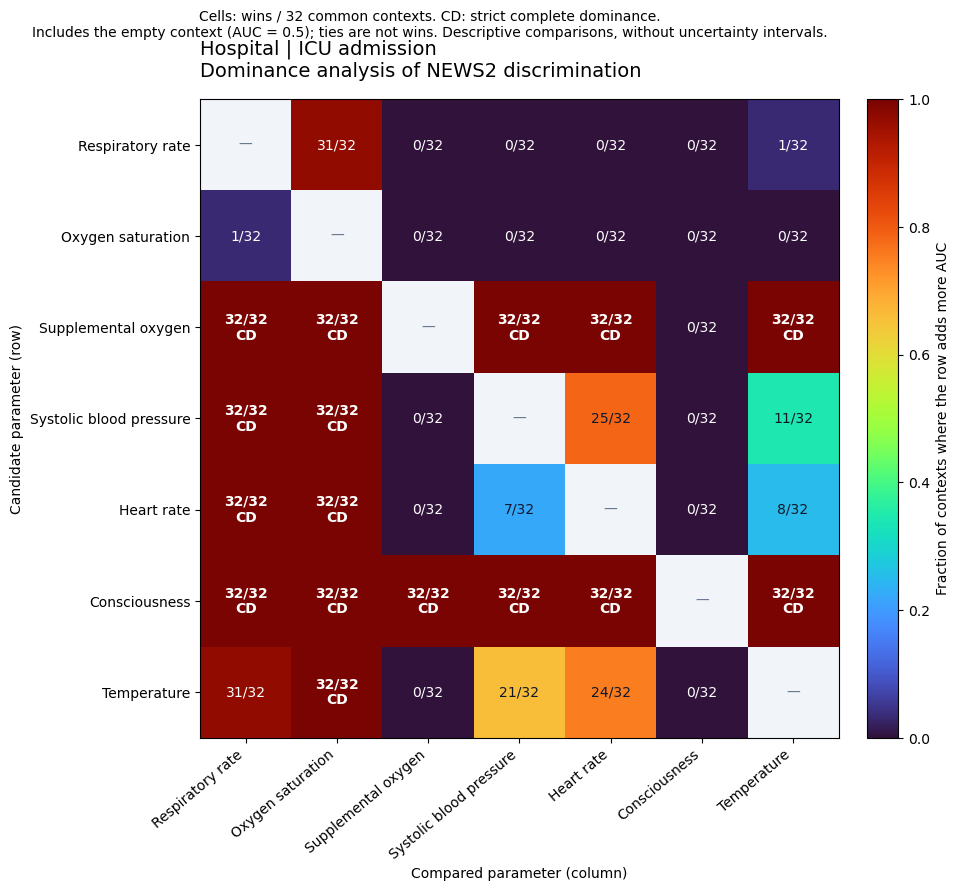

In [20]:
dominance_uvi_hosp, dominance_figure_uvi_hosp = plot_news2_auc_dominance(
    results_uvi_hosp, FEATURES,
    cohort='Hospital', outcome='UVI',
    output_dir=OUTPUT_DIR / "dominance_auc",
)
plt.show()
plt.close(dominance_figure_uvi_hosp)

#### Subset performance and parameter removal

In [21]:
save_subset_plot(
    make_scale_branching_subset_plot(
    results_uvi_hosp, FEATURES, news2_auc=auc_uvi_hosp,
    title='UVI in hospitalized patients',
    ),
    "uvi_hosp_parallel_plots", "parallel_plots",
)

In [22]:
save_subset_plot(
    make_marginal_ablation_plot(
    results_uvi_hosp, FEATURES, title='UVI in hospitalized patients'
    ),
    "uvi_hosp_boxplots", "boxplots",
)

# Final comparison

The table below selects the partial scale with the highest nested-CV balanced accuracy for each cohort/outcome. The complete 127-row CSV files retain every subset and all fold-level results.

In [23]:
experiments = {
    ('Prehospital', 'M30D'): results_m30d_pre,
    ('Prehospital', 'UVI'): results_uvi_pre,
    ('Hospital', 'M30D'): results_m30d_hosp,
    ('Hospital', 'UVI'): results_uvi_hosp,
}
best_rows = []
for (cohort, outcome), result in experiments.items():
    best = result.sort_values(
        ['balanced_accuracy', 'auc', 'n_features'],
        ascending=[False, False, True],
    ).iloc[0]
    best_rows.append({
        'cohort': cohort,
        'outcome': outcome,
        'best_subset': best['subset_label'],
        'n_features': int(best['n_features']),
        'auc': best['auc'],
        'balanced_accuracy': best['balanced_accuracy'],
        'sensitivity': best['sensitivity'],
        'specificity': best['specificity'],
        'threshold_mean': best['threshold_mean'],
    })
summary = pd.DataFrame(best_rows)
summary.to_csv(OUTPUT_DIR / 'best_scale_subsets_summary.csv', index=False)
summary

,cohort,outcome,best_subset,n_features,auc,balanced_accuracy,sensitivity,specificity,threshold_mean
0,Prehospital,M30D,blod_oxy + oxigen + consciousness,3,0.821140,0.758707,0.828746,0.688667,3.0
1,Prehospital,UVI,oxigen + blod_pres + consciousness,3,0.750668,0.726715,0.694110,0.759319,3.0
2,Hospital,M30D,resp_rate + blod_oxy + oxigen + blod_pres + co...,5,0.865328,0.799597,0.809851,0.789343,5.0
3,Hospital,UVI,resp_rate + oxigen + blod_pres + consciousness,4,0.821112,0.775291,0.697620,0.852962,5.0


### Combined Shapley attribution table

Absolute contributions are in AUC units. Percentages use each experiment’s own full-score AUC above chance.

In [24]:
shapley_auc_results = pd.concat(
    [attribution_m30d_pre, attribution_uvi_pre,
     attribution_m30d_hosp, attribution_uvi_hosp],
    ignore_index=True,
)
shapley_auc_results.to_csv(OUTPUT_DIR / "NEWS2_shapley_auc.csv", index=False)
shapley_auc_results.style.format({
    "shapley_auc": "{:.4f}", "percentage": "{:.1f}", "full_auc": "{:.3f}",
})

,parameter,shapley_auc,percentage,full_auc,cohort,outcome
0,resp_rate,0.0455,14.5,0.815,Prehospital,M30D
1,blod_oxy,0.0727,23.1,0.815,Prehospital,M30D
2,oxigen,0.0341,10.9,0.815,Prehospital,M30D
3,blod_pres,0.0283,9.0,0.815,Prehospital,M30D
4,heart_rate,0.0135,4.3,0.815,Prehospital,M30D
5,consciousness,0.1109,35.2,0.815,Prehospital,M30D
6,temp,0.0095,3.0,0.815,Prehospital,M30D
7,resp_rate,0.0273,10.6,0.758,Prehospital,UVI
8,blod_oxy,0.0433,16.8,0.758,Prehospital,UVI
9,oxigen,0.0202,7.8,0.758,Prehospital,UVI


## Prehospital-to-hospital raw-measurement changes

For patients with both time points, the hospital raw measurement is subtracted from the prehospital raw measurement for each component. The AUC quantifies how well that raw-value change alone discriminates each outcome.

In [25]:
component_delta_auc = evaluate_component_raw_deltas(
    data_pre,
    data_hosp,
    feature_order=FEATURES,
    targets=OUTCOMES,
)
component_delta_auc.to_csv(
    OUTPUT_DIR / 'prehospital_to_hospital_raw_delta_auc.csv', index=False
)
component_delta_auc

make_component_delta_auc_plot(component_delta_auc).show()

## Standalone interactive HTML report

In [26]:
from functions.news2_scale_html_report import (
    ScaleExperimentReport,
    create_news2_scale_html,
)

report_experiments = [
    ScaleExperimentReport('Prehospital', 'M30D', results_m30d_pre, auc_m30d_pre),
    ScaleExperimentReport('Prehospital', 'UVI', results_uvi_pre, auc_uvi_pre),
    ScaleExperimentReport('Hospital', 'M30D', results_m30d_hosp, auc_m30d_hosp),
    ScaleExperimentReport('Hospital', 'UVI', results_uvi_hosp, auc_uvi_hosp),
]
report_path = create_news2_scale_html(
    report_experiments,
    FEATURES,
    'NEWS2_scale_deconstruction_report.html',
    component_delta_results=component_delta_auc,
    figures_dir=OUTPUT_DIR,
)
report_path

PosixPath('NEWS2_scale_deconstruction_report.html')

## Optional: patient-level explanations of NEWS2 points

These beeswarm and bar plots explain individual NEWS2 scores relative to a sampled background. They do **not** decompose AUC and are not required for the four discrimination plots above. Each cohort explains up to 500 patients.

In [27]:
# from functions.shap_values import plot_news2_shap

### Prehospital score contributions

In [28]:
# shap_pre, importance_pre = plot_news2_shap(
#     data_pre,
#     FEATURES,
#     cohort_name="Prehospital",
#     max_patients=500,
# )

### Hospital score contributions

In [29]:
# shap_hosp, importance_hosp = plot_news2_shap(
#     data_hosp,
#     FEATURES,
#     cohort_name="Hospital",
#     max_patients=500,
# )